# SnowPredict - Milestone 3: EDA, Initial Modeling, and Pipeline Development

**Project group #8**
**Group members:** Livia Jonnatan, Jiwon Kim, Jihoon Park

**Project question (revised proposal):** For any date in the ski season (December 1 to April 30), how well can a model trained on earlier winter seasons predict a weather-based ski-condition index 7 days ahead at seven Canadian ski resorts? 

**Data source:** [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api). Free, no API key.

**Without network:** To run this notebook without any network, unzip the raw data from [Google Drive](https://drive.google.com/file/d/1Uiq8u6BNzvv_2aBrz4tDBLN_AQpXyeE3/view?usp=share_link) into `/data/raw/` and run the notebook.

<div class="alert alert-info" style="color: #4a4a4a; background-color: #fffad2; border-color: #ffedbb; border-width: 1px; border-radius: 3px; padding: 10px;">

**Notebook order follows:**
1. Load the cleaned data and build the index
2. EDA and plots
3. Build the table --> features known on day t, targets on t+7
4. Reference points: historical average and persistence
5. Pipeline
6. Initial model and results
7. Plan for Milestone 4

*Input:* `data/weather_daily_wide.csv` from Milestone 2 (one row = resort, elevation point, calendar day)

*Conventions:* test seasons 2024-2026 are never touched in this notebook. Every model results is cached under `data/results`/ so re-running does not refit.

In [2]:
import warnings

import os, json, time, glob, datetime
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from matplotlib import cm, colors
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*penalty is deprecated.*")

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11

In [3]:
SEED = 2026
HORIZON = 7
RESULTS = "data/results"
os.makedirs(RESULTS, exist_ok=True)

# 1. Load the cleaned data and build the index

The daily-wide table keeps every calendar day, so lagged features for early December can use November. Season identifiers and the index are the same definitions as MS2.

**Why these splits:** seasons (not rows) are the unit of splitting because adjacent days within a winter are near copies of each other. Training seasons 2006-2020, validation 2021-2023, and test 2024-2026 as per the proposal (MS 2). The test seasons are the most recent winters because this is how a forecasting is usually being judged. Validation and training (development seasons) will be used for any cross-validation.

In [4]:
RESORTS = ["Whistler Blackcomb", "Big White", "Sun Peaks", "Revelstoke",
           "Lake Louise", "Mont Tremblant", "Mont Sainte-Anne"]
REGION = {"Whistler Blackcomb": "west", "Big White": "west", "Sun Peaks": "west", 
          "Revelstoke": "west", "Lake Louise": "west", "Mont Tremblant": "east", "Mont Sainte-Anne": "east"}
POINTS = ["base", "mid", "high"]

In [5]:
TRAIN_SEASONS = list(range(2006, 2021))
VAL_SEASONS = [2021, 2022, 2023]
TEST_SEASONS = [2024, 2025, 2026]
DEV_SEASONS = TRAIN_SEASONS + VAL_SEASONS
assert max(TRAIN_SEASONS) < min(VAL_SEASONS) < min(TEST_SEASONS)

In [6]:
raw = pd.read_csv("data/weather_daily_wide.csv", parse_dates=["date"])
raw = raw.sort_values(["resort", "point", "date"]).reset_index(drop=True)
raw["season"] = np.where(raw["date"].dt.month >= 7, raw["date"].dt.year + 1, raw["date"].dt.year)
raw["day_of_season"] = (raw["date"] - pd.to_datetime((raw["season"] - 1).astype(str) + "-12-01")).dt.days
raw["month"] = raw["date"].dt.month
print("Daily-wide table:", raw.shape, "| missing values:", int(raw.isna().sum().sum()))

Daily-wide table: (164241, 100) | missing values: 0


In [ ]:
# As per MS 2
# Weights are adapted from the skier-preference survey literature (see proposal)
# Sensitivity to the weights will be checked later

def ski_index(df, w_depth=0.30, w_fresh=0.15, w_sun=0.10, w_temp=0.20, w_wind=0.10, w_rain=0.15):
    depth = (df["snow_depth_mean_am"] / 100).clip(0, 1)
    fresh = (df["snowfall_sum_night"] / 15).clip(0, 1)
    sun = (df["sunshine_hours"] / df["daylight_hours"]).clip(0, 1)
    day_t = (df["temp_mean_am"] + df["temp_mean_pm"]) / 2
    temp = 1 - ((day_t + 4).abs().clip(0, 16) / 16)
    wind = 1 - ((df["gust_max_am"].combine(df["gust_max_pm"], max) - 50).clip(0, 50) / 50)
    rain = 1 - ((df["rain_sum_am"] + df["rain_sum_pm"]).clip(0, 5) / 5)
    return 100 * (w_depth * depth + w_fresh * fresh + w_sun * sun + w_temp * temp + w_wind * wind + w_rain * rain)

In [8]:
def index_components(df):
    return pd.DataFrame({
        "depth": (df["snow_depth_mean_am"] / 100).clip(0, 1),
        "fresh": (df["snowfall_sum_night"] / 15).clip(0, 1),
        "sun": (df["sunshine_hours"] / df["daylight_hours"]).clip(0, 1),
        "temp": 1 - (((df["temp_mean_am"] + df["temp_mean_pm"]) / 2+4).abs().clip(0, 16) / 16),
        "wind": 1 - ((df["gust_max_am"].combine(df["gust_max_pm"], max) - 50).clip(0, 50) / 50),
        "rain": 1 - ((df["rain_sum_am"] + df["rain_sum_pm"]).clip(0, 5) / 5),
    }, index=df.index)

In [9]:
WEIGHTS = {"depth": 0.30, "fresh": 0.15, "sun": 0.10, "temp":0.20, "wind":0.10, "rain":0.15}

raw["ski_index"] = ski_index(raw)

In [10]:
def in_ski_window(dates):
    m = dates.dt.month
    return (m == 12) | (m <= 4)

In [ ]:
ski = raw[in_ski_window(raw["date"]) & raw["season"].between(2006, 2026)].copy()
ski["split"] = np.select([ski["season"].isin(TRAIN_SEASONS), ski["season"].isin(VAL_SEASONS), ski["season"].isin(TEST_SEASONS)], ["train", "val", "test"], default="unused")

# mid-mountain is the prediction point
# at MS2 we found the 3 points differ mostly in temperature (we can adjust later)
mid = ski[ski["point"] == "mid"].copy()
print("Ski-season table:", ski.shape, "| mid point only:", mid.shape)
ski.groupby("split")["season"].agg(n_rows="size", seasons="nunique")

Ski-season table: (66696, 102) | mid point only: (22232, 102)


,n_rows,seasons
split,,
test,9534,3
train,47649,15
val,9513,3


# 2. Exploratory Data Analysis

The question fixes the target (the index 7 days ahead) and the comparison (historical day-of-season average). So the EDA asks four things: what the target looks like, how much of it the calendar alone explains, how much of it today's state explains, and which variables at day t relate to the target at t+7.

Morning snow depth is tracked along with the index, because it is the index's largest term and in units that's easy to explain and understand.

All EDA uses the **mid** point at the development seasons (2006-2023) only.

## 2.1 What does the target look like?

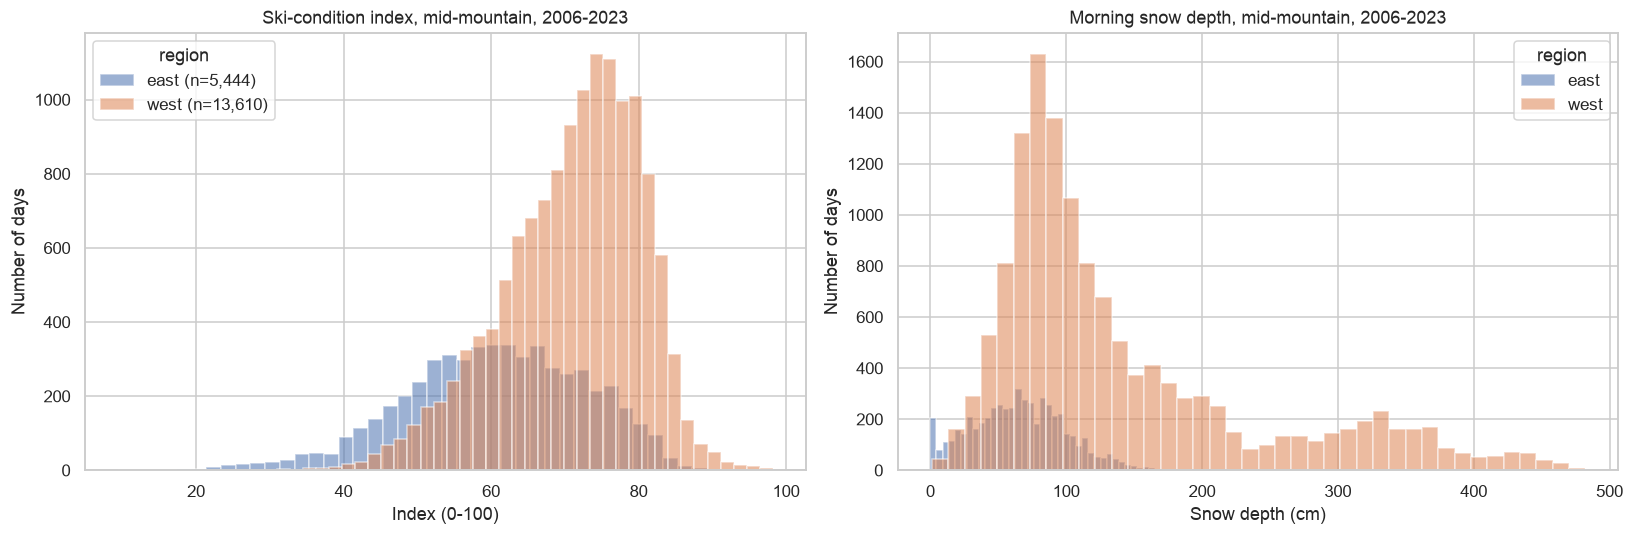

ski_index                   snow_depth_mean_am                   
                        mean   std   min   max               mean   std   min    max
resort                                                                              
Big White               68.0   9.7  30.0  90.8               77.0  25.3   1.2  140.8
Lake Louise             70.5   8.3  40.9  90.9              100.7  23.1  26.2  158.8
Mont Sainte-Anne        64.5  11.3  18.5  89.3               79.3  34.4   0.0  179.0
Mont Tremblant          56.5  11.8   9.4  88.7               51.0  27.9   0.0  132.0
Revelstoke              74.7   7.0  47.1  92.4              158.5  36.9  54.5  235.0
Sun Peaks               64.9   9.2  27.4  85.3               65.8  20.6   4.0  120.0
Whistler Blackcomb      77.2   6.9  48.3  98.2              305.4  82.0  75.0  482.2

In [12]:
dev = mid[mid["season"].isin(DEV_SEASONS)]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for region, g in dev.groupby("region"):
    axes[0].hist(g["ski_index"], bins=40, alpha=0.55, label=f"{region} (n={len(g):,})")
    axes[1].hist(g["snow_depth_mean_am"], bins=40, alpha=0.55, label=region)
axes[0].set_title("Ski-condition index, mid-mountain, 2006-2023")
axes[0].set_xlabel("Index (0-100)")
axes[0].set_ylabel("Number of days")
axes[0].legend(title="region")
axes[1].set_title("Morning snow depth, mid-mountain, 2006-2023")
axes[1].set_xlabel("Snow depth (cm)")
axes[1].set_ylabel("Number of days")
axes[1].legend(title="region")
fig.tight_layout()
plt.show()

dev.groupby("resort")[["ski_index", "snow_depth_mean_am"]].agg(["mean", "std", "min", "max"]).round(1)

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** 

## 2.2 How much does the calendar alone explain?

The historical day-of-season average is our **baseline**. If the index follows a tight seasonal curve, the baseline is hard to beat. If the spread around the curve is wide, there is room for a model.

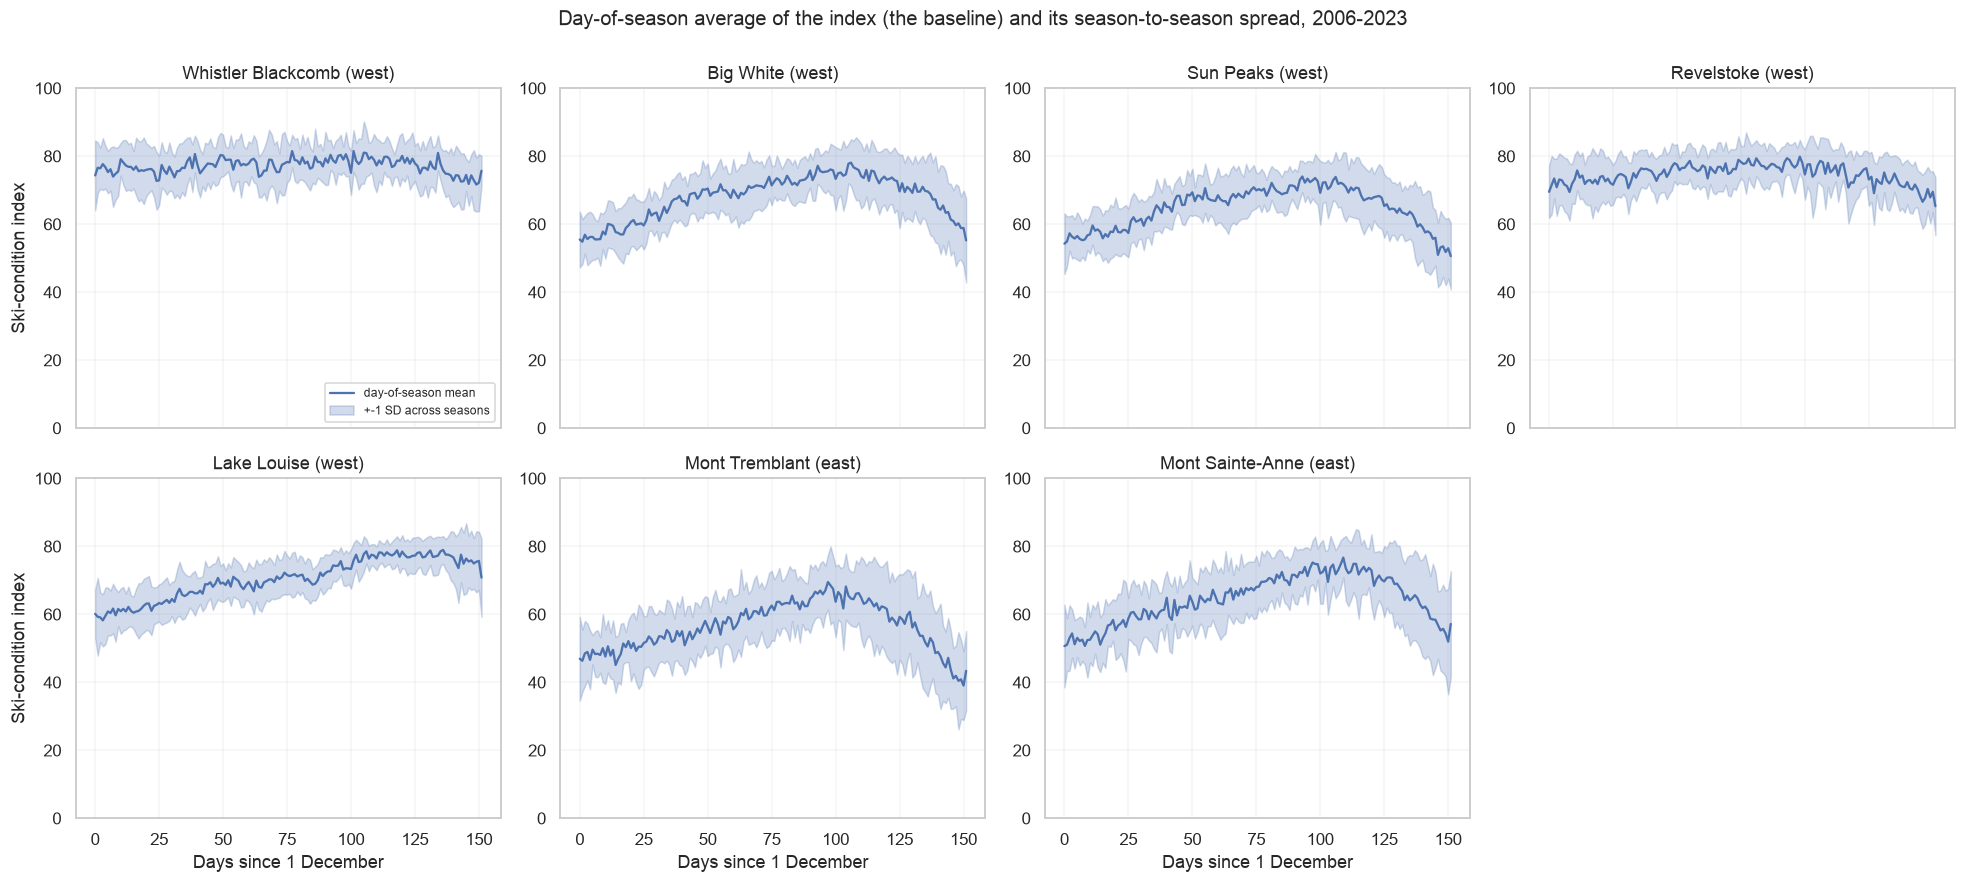

In [13]:
clim_curve = dev.groupby(["resort", "day_of_season"]).agg(idx_mean=("ski_index", "mean"), idx_sd=("ski_index", "std"), 
                                                          sd_mean=("snow_depth_mean_am", "mean"), sd_sd=("snow_depth_mean_am", "std")).reset_index()
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
for ax, name in zip(axes.flat, RESORTS):
    c = clim_curve[clim_curve["resort"] == name]
    ax.plot(c["day_of_season"], c["idx_mean"], color="C0", label="day-of-season mean")
    ax.fill_between(c["day_of_season"], c["idx_mean"] - c["idx_sd"], c["idx_mean"] + c["idx_sd"], color="C0", alpha=0.25, label="+-1 SD across seasons")
    ax.set_title(f"{name} ({REGION[name]})")
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.2)
for ax in axes[1, :3]:
    ax.set_xlabel("Days since 1 December")
for ax in axes[:, 0]:
    ax.set_ylabel("Ski-condition index")
axes.flat[-1].set_visible(False)
axes.flat[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Day-of-season average of the index (the baseline) and its season-to-season spread, 2006-2023", y=1)
fig.tight_layout()
plt.show()

In [14]:
def calendar_r2(df, col):
    fitted = df.groupby(["resort", "day_of_season"])[col].transform("mean")
    return 1 - ((df[col] - fitted) ** 2).sum() / ((df[col] - df[col].mean()) ** 2).sum()

In [15]:
pd.DataFrame({
    "calendar R2 (pooled)": {"ski_index": calendar_r2(dev, "ski_index"), "snow_depth_mean_am": calendar_r2(dev, "snow_depth_mean_am")},
    "mean SD around the curve": {"ski_index": clim_curve["idx_sd"].mean(), "snow_depth_mean_am": clim_curve["sd_sd"].mean()},
}).round(2)

,calendar R2 (pooled),mean SD around the curve
ski_index,0.56,7.44
snow_depth_mean_am,0.90,26.27


<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** 

## 2.3 Which terms carry the index?

The index is a weighted sum of six 0-1 terms. If one term dominates its variance, predicting that term well matters most.

In [16]:
comp = index_components(dev)
weighted = comp.mul(pd.Series(WEIGHTS)) * 100
share_mean = weighted.groupby(dev["resort"]).mean().reindex(RESORTS)

var_share = pd.Series({c: np.cov(weighted[c], dev["ski_index"]) [0, 1] / dev["ski_index"].var() for c in weighted.columns})

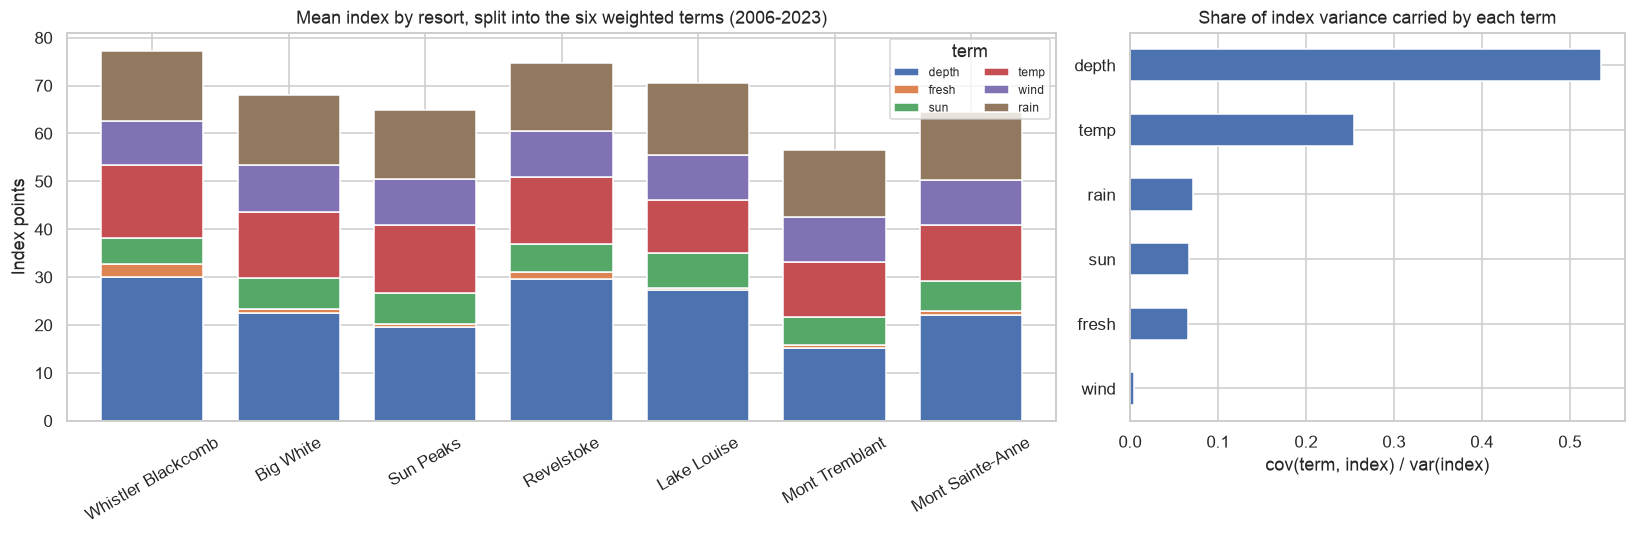

depth    0.536
temp     0.254
rain     0.072
sun      0.067
fresh    0.066
wind     0.005
dtype: float64

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15,5), gridspec_kw={"width_ratios": [2,1]})
share_mean.plot.bar(stacked=True, ax=axes[0], width=0.75)
axes[0].set_title("Mean index by resort, split into the six weighted terms (2006-2023)")
axes[0].set_ylabel("Index points")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="term", fontsize=8, ncol=2)
var_share.sort_values().plot.barh(ax=axes[1], color="C0")
axes[1].set_title("Share of index variance carried by each term")
axes[1].set_xlabel("cov(term, index) / var(index)")
fig.tight_layout()
plt.show()
var_share.round(3).sort_values(ascending=False)

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** 

## 2.4 How much does today's state explain?

Persistence ("the index in 7 days equals the index today") is another baseline, and the lag features in section 3 are built on the same idea. Autocorrelation on the raw series mixes in the calendar, so we also use the anomaly from the day-of-season mean (MS 2).

In [18]:
dev = dev.sort_values(["resort", "date"]).copy()
for col in ["ski_index", "snow_depth_mean_am"]:
    lead = dev.groupby(["resort", "season"])[col].shift(-HORIZON)
    dev[f"{col}_lead{HORIZON}"] = lead
pairs = dev.dropna(subset=[f"ski_index_lead{HORIZON}", f"snow_depth_mean_am_lead{HORIZON}"])

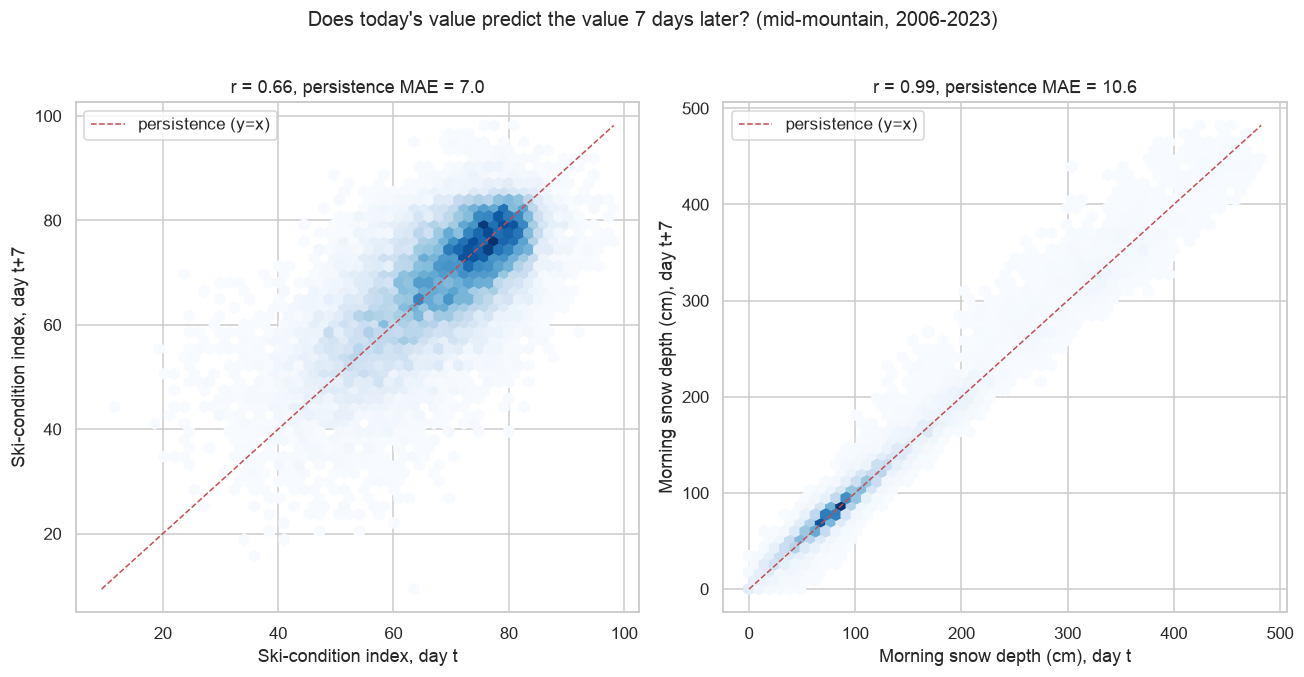

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12,6))
for ax, col, lab in zip(axes, ["ski_index", "snow_depth_mean_am"], ["Ski-condition index", "Morning snow depth (cm)"]):
    x, y = pairs[col], pairs[f"{col}_lead{HORIZON}"]
    ax.hexbin(x, y, gridsize=50, cmap="Blues", mincnt=1)
    lim = [min(x.min(), y.min()), max(x.max(), y.max())]
    ax.plot(lim, lim, "r--", lw=1, label="persistence (y=x)")
    ax.set_xlabel(f"{lab}, day t")
    ax.set_ylabel(f"{lab}, day t+{HORIZON}")
    ax.set_title(f"r = {np.corrcoef(x,y)[0,1]:.2f}, persistence MAE = {np.abs(y-x).mean():.1f}")
    ax.legend(loc="upper left")
fig.suptitle(f"Does today's value predict the value {HORIZON} days later? (mid-mountain, 2006-2023)", y=1.02)
fig.tight_layout()
plt.show()

In [20]:
# Pooled anomaly autocorrelation at lag 7: remove the calendar, keep this winter's level (MS2)
targets_ac = ["snow_depth_mean_am", "ski_index", "temperature_2m_mean", "sunshine_hours", "rain_sum", "wind_gusts_10m_max"]
clim_mean = dev.groupby(["resort", "day_of_season"])[targets_ac].transform("mean")
anom = dev[["resort", "season", "date"]].join(dev[targets_ac] - clim_mean)

In [21]:
def pooled_anomaly_ac(a, col, lag=HORIZON):
    xs, ys = [], []
    for _, g in a.groupby(["resort", "season"]):
        v = g.sort_values("date")[col].to_numpy()
        xs.append(v[:-lag])
        ys.append(v[lag:])
    return np.corrcoef(np.concatenate(xs), np.concatenate(ys))[0,1]

In [22]:
ac = pd.DataFrame([{"resort": r, "variable": t, "ac": pooled_anomaly_ac(anom[anom["resort"] == r], t)} for r in RESORTS for t in targets_ac])
ac.pivot(index="variable", columns="resort", values="ac").reindex(targets_ac).round(2)

resort,Big White,Lake Louise,Mont Sainte-Anne,Mont Tremblant,Revelstoke,Sun Peaks,Whistler Blackcomb
variable,,,,,,,
snow_depth_mean_am,0.91,0.91,0.89,0.87,0.88,0.89,0.89
ski_index,0.45,0.29,0.37,0.40,0.11,0.40,0.07
temperature_2m_mean,0.17,0.17,0.14,0.14,0.16,0.18,0.20
sunshine_hours,0.04,0.03,0.04,0.04,0.01,0.02,0.02
rain_sum,0.04,0.02,0.02,0.02,0.07,0.06,0.05
wind_gusts_10m_max,0.00,0.03,0.07,0.05,0.03,0.22,0.06


<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** 

## 2.5 Which variables at day t relate to the target at t+7?

A step before feature engineering here. Correlation of each daily variable on day t with the two targets on day t+7, within the development seasons.

In [23]:
screen_vars = ["snow_depth_mean_am", "snow_depth_mean_pm", "snowfall_sum", "snowfall_sum_night", "rain_sum", "precipitation_sum", "temperature_2m_mean", "temperature_2m_max", "temperature_2m_min", "temp_min_night",
               "hours_above_0c_pm", "wet_bulb_temperature_2m_mean", "dew_point_2m_mean", "relative_humidity_2m_mean", "sunshine_hours", "cloud_cover_mean", "shortwave_radiation_sum", "wind_speed_10m_max", "wind_gusts_10m_max",
               "surface_pressure_mean", "soil_temperature_0_to_7cm_mean", "day_of_season", "ski_index"]
corr = pd.DataFrame({
    f"index t+{HORIZON}": pairs[screen_vars].corrwith(pairs[f"ski_index_lead{HORIZON}"]),
    f"snow depth t+{HORIZON}": pairs[screen_vars].corrwith(pairs[f"snow_depth_mean_am_lead{HORIZON}"]),
})

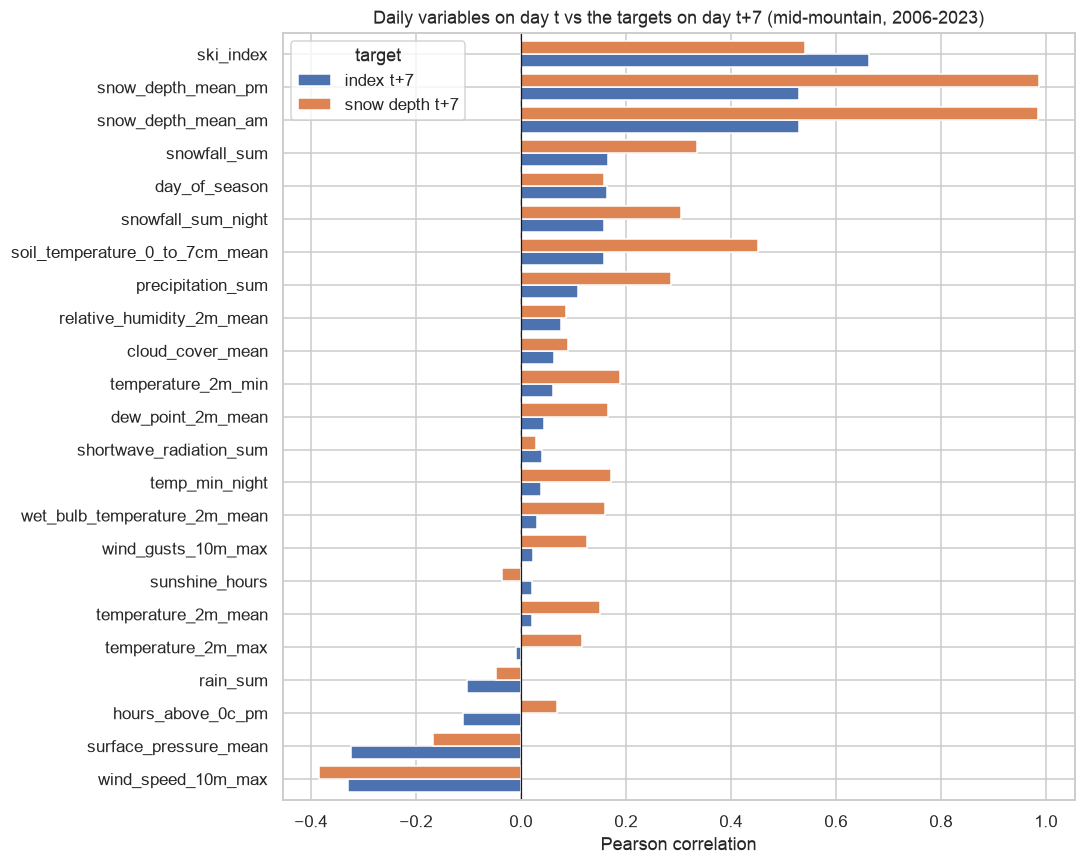

,index t+7,snow depth t+7
ski_index,0.66,0.54
snow_depth_mean_pm,0.53,0.99
snow_depth_mean_am,0.53,0.99
snowfall_sum,0.17,0.34
snowfall_sum_night,0.16,0.31
day_of_season,0.16,0.16
soil_temperature_0_to_7cm_mean,0.16,0.45
precipitation_sum,0.11,0.29
relative_humidity_2m_mean,0.08,0.09
temperature_2m_min,0.06,0.19


In [24]:
fig, ax = plt.subplots(figsize=(10,8))
corr.sort_values(f"index t+{HORIZON}").plot.barh(ax=ax, width=0.8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Pearson correlation")
ax.set_title(f"Daily variables on day t vs the targets on day t+{HORIZON} (mid-mountain, 2006-2023)")
ax.legend(title="target")
fig.tight_layout()
plt.show()
corr.round(2).sort_values(f"index t+{HORIZON}", ascending=False).head(10)

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** 

# 3. Building the table: features at t, targets at t+7

One row per (resort, prediction date t) on the mid point. Features use rows with date <= t only. Targets are the index and morning snow depth on t+7. The table is built on the full-year series so the November lags exist for early December, then restricted to prediction dates whose target date is also inside the ski season.

Every feature is measured on or before day t. The target is built from the weather on day t+7, which is not in the table.

**Feature choices and why:**
- Current day: every daily and daypart variable for day t. The night before t is over by the time we predict. So overnight snowfall is included.
- Lags 1, 3, 7, 14 days of snow depth, temperature and the index, rolling sums over 3, 7, 14, 30 days of snowfall and rain, and rollng means of temperature, sunshine, and the index. Short windows because the memory that exists is short. 14 and 30 is so that a slow melt or a long dry season is visible.
- Elevation: base-minus-high mean temperature. This was the thing MS2 found the three points differ on
- Resort: one indicator per resort plus an east/west flag. So the linear models can shift level by resort
- Season as a number: so a linear model can follow the warming trend (found in MS2)

In [25]:
# day-t variables (daily block + dayparts of day t). The night before t is over by the time we predict.
CURRENT = [
    "snow_depth_mean_am", "snow_depth_mean_pm", "snowfall_sum", "snowfall_sum_night", "rain_sum", "precipitation_sum", "precipitation_hours","temperature_2m_mean", "temperature_2m_max", "temperature_2m_min", 
    "temp_min_night", "temp_mean_am", "temp_mean_pm", "hours_above_0c_pm", "wet_bulb_temperature_2m_mean", "dew_point_2m_mean", "relative_humidity_2m_mean", "sunshine_hours", "daylight_hours", "cloud_cover_mean", 
    "shortwave_radiation_sum", "wind_speed_10m_max", "wind_gusts_10m_max", "gust_max_pm", "surface_pressure_mean", "soil_temperature_0_to_7cm_mean", "ski_index",
]
LAG_VARS = ["snow_depth_mean_am", "temperature_2m_mean", "ski_index"]
LAGS = [1, 3, 7, 14]
ROLL_SUM_VARS = ["snowfall_sum", "rain_sum"]
ROLL_MEAN_VARS = ["temperature_2m_mean", "sunshine_hours", "ski_index"]
WINDOWS = [3, 7, 14, 30]
TARGETS = ["ski_index", "snow_depth_mean_am"]

In [26]:
def days_since(s, thresh):
    #days since the last day with s >= thresh, capped at 60 (uses only past data)
    out, cnt = np.empty(len(s)), 60
    for i, v in enumerate(s.to_numpy()):
        cnt = 0 if v >= thresh else min(cnt+1, 60)
        out[i] = cnt
    return pd.Series(out, index=s.index)

In [27]:
def build_supervised(daily, horizon=HORIZON):
    m = daily[daily["point"] == "mid"].sort_values(["resort", "date"]).copy()
    hi = daily[daily["point"] == "high"][["resort", "date", "temperature_2m_mean"]].rename(columns={"temperature_2m_mean": "temp_high"})
    lo = daily[daily["point"] == "base"][["resort", "date", "temperature_2m_mean"]].rename(columns={"temperature_2m_mean": "temp_base"})
    m = m.merge(hi, on=["resort", "date"], validate="one_to_one").merge(lo, on=["resort", "date"], validate="one_to_one")
    m["temp_base_minus_high"] = m["temp_base"] - m["temp_high"]
    m["sun_frac"] = (m["sunshine_hours"] / m["daylight_hours"]).clip(0, 1)
    m["freeze_thaw"] = ((m["temperature_2m_max"] > 0) & (m["temperature_2m_min"] < 0)).astype(float)
    g = m.groupby("resort", sort=False)

    f = {}
    for v in LAG_VARS:
        for L in LAGS:
            f[f"{v}_lag{L}"] = g[v].shift(L)
    for v in ROLL_SUM_VARS:
        for w in WINDOWS:
            f[f"{v}_sum{w}"] = g[v].transform(lambda s, w=w: s.rolling(w, min_periods=w).sum())
    for v in ROLL_MEAN_VARS:
        for w in WINDOWS:
            f[f"{v}_mean{w}"] = g[v].transform(lambda s, w=w: s.rolling(w, min_periods=w).mean())
    f["snow_depth_change3"] = m["snow_depth_mean_am"] - g["snow_depth_mean_am"].shift(3)
    f["snow_depth_change7"] = m["snow_depth_mean_am"] - g["snow_depth_mean_am"].shift(7)
    f["days_since_snow10"] = g["snowfall_sum"].transform(days_since, thresh=10)
    f["freeze_thaw_days7"] = g["freeze_thaw"].transform(lambda s: s.rolling(7, min_periods=7).sum())
    f["doy_sin"] = np.sin(2 * np.pi * m["day_of_season"] / 365)
    f["doy_cos"] = np.cos(2 * np.pi * m["day_of_season"] / 365)
    # targets on day t + horizon (shift by rows within the contiguous daily series of each resort)
    t = {f"y_{v}": g[v].shift(-horizon) for v in TARGETS}
    t["y_date"] = g["date"].shift(-horizon)

    out = pd.concat([m, pd.DataFrame(f, index=m.index), pd.DataFrame(t, index=m.index)], axis=1)
    keep = in_ski_window(out["date"]) & in_ski_window(out["y_date"]) & out["season"].between(2006, 2026)
    keep &= (out["y_date"] - out["date"]).dt.days == horizon
    out = out[keep].copy()
    out["region_east"] = (out["resort"].map(REGION) == "east").astype(int)
    for r in RESORTS:
        out["resort_" + r.replace(" ", "_").replace("-", "_")] = (out["resort"] == r).astype(int)
    out["y_dos"] = out["day_of_season"] + horizon          # day-of-season of the target date, for the climatology lookup
    return out.dropna(subset=[f"y_{v}" for v in TARGETS]).reset_index(drop=True)

In [ ]:
t0 = time.time()
sup = build_supervised(raw)
ENGINEERED = [c for c in sup.columns if any (c.endswith(s) for s in [f"_lag{L}" for L in LAGS] + [f"_sum{w}" for w in WINDOWS] + [f"_mean{w}" for w in WINDOWS])]
EXTRA = ["snow_depth_change3", "snow_depth_change7", "days_since_snow10", "freeze_thaw_days7", "doy_sin", "doy_cos", "day_of_season", "season", "sun_frac", "temp_base_minus_high", "region_east"]
FEATURES = CURRENT + ENGINEERED + EXTRA + [c for c in sup.columns if c.startswith("resort_")]
Y_INDEX = "y_ski_index"
Y_DEPTH = "y_snow_depth_mean_am"
print(f"Supervised table: {sup.shape[0]:,} rows, {len(FEATURES)} features, built in {time.time()-t0:.0f}s")
print(f"Prediction dates run from day {sup["day_of_season"].min()} to day {sup["day_of_season"].max()} of the season (December 1 to about April 23), target dates reach 30 April | rows per season: {sup.groupby("season").size().min()} - {sup.groupby("season").size().max()}")
sup[["resort", "date", "y_date", "season", "day_of_season", "y_dos", "ski_index", Y_INDEX, "snow_depth_mean_am", Y_DEPTH]].head()

Supervised table: 21,203 rows, 77 features, built in 0s
Prediction dates run from day 0 to day 144 of the season (December 1 to about April 23), target dates reach 30 April | rows per season: 1008 - 1015


,resort,date,y_date,season,day_of_season,y_dos,ski_index,y_ski_index,snow_depth_mean_am,y_snow_depth_mean_am
0,Big White,2005-12-01,2005-12-08,2006,0,7,50.520613,54.599465,44.00,48.0
1,Big White,2005-12-02,2005-12-09,2006,1,8,50.830417,59.969628,47.50,48.0
2,Big White,2005-12-03,2005-12-10,2006,2,9,53.876543,62.022787,48.00,47.0
3,Big White,2005-12-04,2005-12-11,2006,3,10,50.817279,59.898194,47.00,46.0
4,Big White,2005-12-05,2005-12-12,2006,4,11,54.558614,59.176246,48.25,46.0


## 3.1 Leakage checks

In [29]:
# every target date is exactly HORIZON days after its prediction date
assert ((sup["y_date"] - sup["date"]).dt.days == HORIZON).all()

# no feature column is a target or derived from a date after t --> rebuild the features with the future removed and compare
future_cut = raw.copy()
cut_date = pd.Timestamp("2015-02-01")
future_cut.loc[future_cut["date"] > cut_date, [c for c in raw.columns if c not in ("resort", "point", "date", "season", "day_of_season", "month")]] = np.nan
sup_cut = build_supervised(future_cut)
row_a = sup[(sup["resort"] == "Big White") & (sup["date"] == cut_date)][FEATURES].iloc[0]
row_b = sup_cut[(sup_cut["resort"] == "Big White") & (sup_cut["date"] == cut_date)]
assert len(row_b) == 0 or np.allclose(row_a.values.astype(float), row_b[FEATURES].iloc[0].values.astype(float), equal_nan=True)

# the dat after the cut must have no complete feature row at all (its features need data after the cut)
print("Rows with a complete feature vector after the cut: ", int(sup_cut[sup_cut["date"] > cut_date][FEATURES].notna().all(axis=1).sum()))

# no missing values in features or targets
print("Missing feature values:", int(sup[FEATURES].isna().sum().sum()), " | missing targets: ", int(sup[[Y_INDEX, Y_DEPTH]].isna().sum().sum()))

# "season" is a feature (long-run trend), but it is never a target identifier
# test seasons are held out below
print("Features that are the target itself:", [c for c in FEATURES if c.startswith("y_")])

Rows with a complete feature vector after the cut:  0
Missing feature values: 0  | missing targets:  0
Features that are the target itself: []


<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** 

In [30]:
pd.DataFrame({"group": ["current day (daily + dayparts)", "lags/rolling window", "snowpack memory, calendar, elevation gradient", "resort indicators"],
              "n": [len(CURRENT), len(ENGINEERED), len(EXTRA), len([c for c in FEATURES if c.startswith("resort_")])]}).set_index("group")

,n
group,
current day (daily + dayparts),27
lags/rolling window,32
"snowpack memory, calendar, elevation gradient",11
resort indicators,7


# 4. Baselines

**Historical day-of-season average (climatology):** for a target on day-of-season *d* at resort *r*, the mean of that target on day *d* over the **training seasons only** (staff condition), smoothed over a +-3-day window. So a single day in a single season cannot dominate.

**Persistence:** the value on day t carried forward to t+7.

Both are first scored n the fixed validation seasons (train 2006-2020, validate 2021-2023) to set the bar, then inside every cross-validation fold.

In [31]:
def climatology_predict(train, test, target, smooth=3):
    #day-of-season mean of "target" at the target date, computed on trains only, looked up for tests
    parts = [train[["resort", "y_dos", target]].assign(y_dos=train["y_dos"] + s) for s in range(-smooth, smooth+1)]
    pooled = pd.concat(parts).groupby(["resort", "y_dos"])[target].mean().rename("clim")
    return test[["resort", "y_dos"]].merge(pooled, on=["resort", "y_dos"], how="left")["clim"].to_numpy()

def persistence_predict(test, target):
    return test[target.replace("y_", "", 1)].to_numpy()

def metrics(y, yhat, y_clim=None):
    y, yhat = np.asarray(y), np.asarray(yhat)
    out = {"MAE": mean_absolute_error(y, yhat), "RMSE": np.sqrt(mean_squared_error(y, yhat)), "R2": r2_score(y, yhat)}
    if y_clim is not None:
        out["skill"] = 1-out["MAE"] / mean_absolute_error(y, y_clim) # fraction of the baseline's MAE removed
    return out

In [32]:
tr= sup[sup["season"].isin(TRAIN_SEASONS)]
va = sup[sup["season"].isin(VAL_SEASONS)]
rows = []
for target, label in [(Y_INDEX, "index"), (Y_DEPTH, "snow depth (cm)")]:
    clim = climatology_predict(tr, va, target)
    rows.append({"target": label, "baseline": "climatology", **metrics(va[target], clim, clim)})
    rows.append({"target": label, "baseline": "persistence", **metrics(va[target], persistence_predict(va, target), clim)})
baseline_tbl = pd.DataFrame(rows).set_index(["target", "baseline"]).round(3)
baseline_tbl

MAE    RMSE     R2  skill
target          baseline                                 
index           climatology   5.715   7.674  0.549  0.000
                persistence   7.104   9.225  0.348 -0.243
snow depth (cm) climatology  18.206  25.855  0.923  0.000
                persistence  10.402  15.156  0.973  0.429

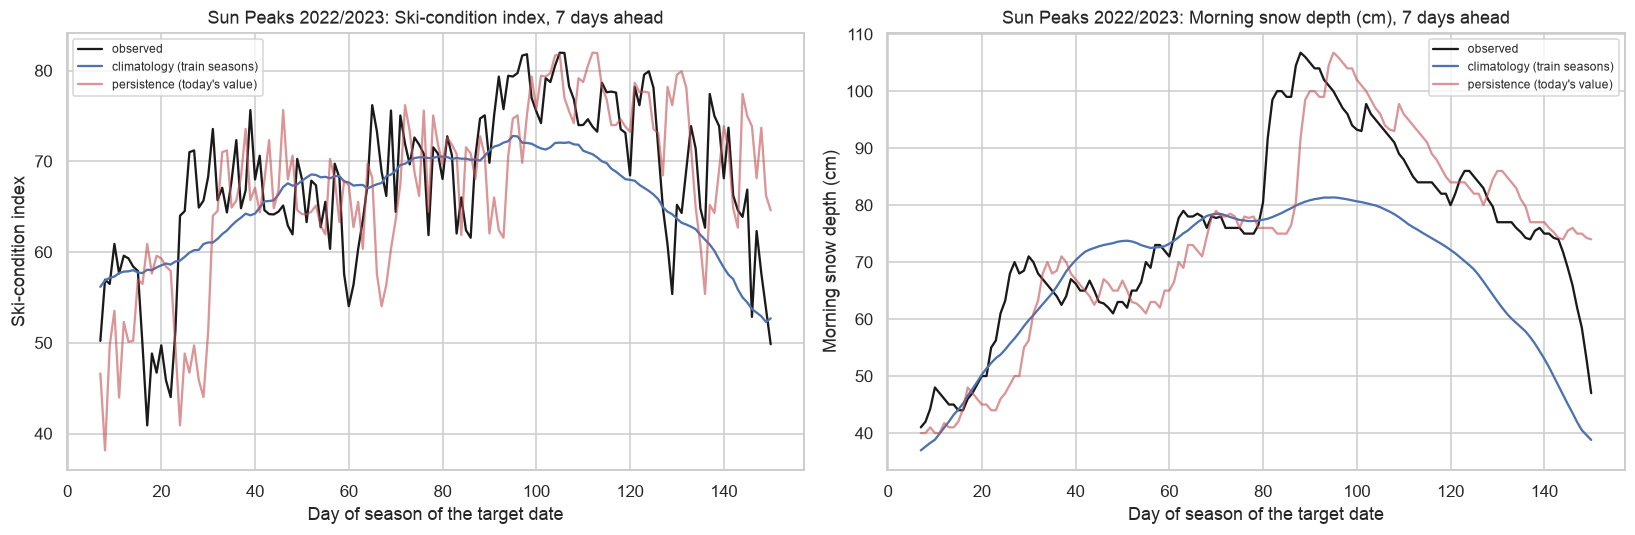

In [33]:
# Let's see what the two baselines look like against one validation winter
name, s = "Sun Peaks", 2023
v = va[(va["resort"] == name) & (va["season"] == s)]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, target, lab in zip(axes, [Y_INDEX, Y_DEPTH], ["Ski-condition index", "Morning snow depth (cm)"]):
    ax.plot(v["y_dos"], v[target], color="k", label="observed")
    ax.plot(v["y_dos"], climatology_predict(tr, v, target), color="C0", label="climatology (train seasons)")
    ax.plot(v["y_dos"], persistence_predict(v, target), color="C3", alpha=0.6, label="persistence (today's value)")
    ax.set_title(f"{name} {s-1}/{s}: {lab}, {HORIZON} days ahead")
    ax.set_xlabel("Day of season of the target date")
    ax.set_ylabel(lab)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** 

# 5. Pipeline: training, validation, and evaluation

1. **Prepare the prediction data.** We use the supervised table `sup` from Section 3. Each row represents one resort on a prediction date `t`. We use `FEATURES`, which includes weather information from day `t` and earlier, recent weather summaries, and resort and calendar information.
The primary target is the ski-condition index seven days later (`Y_INDEX`). Morning snow depth (`Y_DEPTH`) is a secondary target. Both dates must fall within the ski season. Because some predictors summarize the full day, we assume predictions are made after the day-`t` weather records are available.

2. **Train on earlier winters and validate on later winters.** We train the initial models on seasons ending in 2006–2020 and evaluate them on seasons ending in 2021–2023. We fit any preprocessing, such as standardization for Ridge regression, using the training rows only.
For later tuning, we plan to use .....TBD

3. **Compare predictions on the same validation rows.(primary metric?)** We compare the models with the historical day-of-season average and persistence from Section 4. We report both MAE and RMSE. MAE shows how far off our predictions are on average, while RMSE gives larger errors more weight. 
We also report R² and MAE-based skill relative to the historical average. When evaluating a cross-validation fold, we calculate its historical average using that fold's training winters only.

5. **Evaluate the final model on held-out winters.** After choosing the model and its settings, we plan to refit it on the combined training and validation seasons (2006–2023). We will then evaluate it on the held-out seasons ending in 2024–2026 using the same metrics. For that comparison, we will calculate the historical average from the combined 2006–2023 seasons.

   

In [47]:
# WORK IN PROGRESS 

def fit_and_evaluate(model, train, validation, target):
    """Fit a model and score it against climatology on the validation rows."""
    fitted_model = clone(model)
    fitted_model.fit(train[FEATURES], train[target])

    predictions = fitted_model.predict(validation[FEATURES])
    climatology = climatology_predict(train, validation, target)
    scores = metrics(validation[target], predictions, y_clim=climatology)

    return fitted_model, predictions, scores

# 6. Initial models

## 6.1 Ski-condition index, 7 days ahead

In [35]:
# TODO

## 6.2 Morning snow depth, 7 days ahead

In [36]:
# TODO

## 6.3 Results side by side

In [37]:
# TODO

## 6.4 WHere does the best model win? By resort and by month

In [38]:
# TODO

## 6.5 Predicted vs observed and a first look at the drivers

In [39]:
# TODO

## 6.6 One variant: predict the deviation from climatology

In [40]:
# todo

<div class="alert alert-info" style="color: #4a4a4a; background-color: #ffe8f5; border-color: #feddef; border-width: 1px; border-radius: 3px; padding: 10px;">

**What it shows:** 

# 7. What we learned and plan for Milestone 4

**Did the EDA change the question?**